In [1]:
import os
path = r"C:\X\fma-project\archive\fma_small\fma_small"
files = os.listdir(path)

print(files[:10])

['000', '001', '002', '003', '004', '005', '006', '007', '008', '009']


In [2]:
import torch
import torchaudio

print("Torch:", torch.__version__)
print("Torchaudio:", torchaudio.__version__)

Torch: 2.11.0+cu126
Torchaudio: 2.11.0+cu126


In [3]:
file = os.path.join(path, "000","000002.mp3")
waveform, sample_rate = torchaudio.load(file)

print("Original sample rate:", sample_rate)
print("Original waveform shape:", waveform.shape)

Original sample rate: 44100
Original waveform shape: torch.Size([2, 1321967])


In [4]:
target_sample_rate = 16000

waveform = torchaudio.functional.resample(waveform,sample_rate,target_sample_rate)

sample_rate = target_sample_rate

print("New sample rate:", sample_rate)
print("New waveform shape:", waveform.shape)

New sample rate: 16000
New waveform shape: torch.Size([2, 479626])


In [5]:
waveform = waveform.mean(dim=0, keepdim=True)
print(waveform.shape)

duration = 10
num_samples = target_sample_rate * duration

print("Samples needed:", num_samples)

torch.Size([1, 479626])
Samples needed: 160000


In [6]:
total_samples = waveform.shape[1]

print("Total samples:", total_samples)
print("Duration:", total_samples / target_sample_rate, "seconds")
max_start = total_samples - num_samples

if max_start < 0:
    # Clip is shorter than the target duration -- pad with zeros on the end
    # instead of cropping, so this doesn't crash on short/corrupted files.
    pad_amount = -max_start
    waveform = torch.nn.functional.pad(waveform, (0, pad_amount))
    total_samples = waveform.shape[1]
    max_start = 0

start = torch.randint(0, max_start + 1,(1,)).item()

print("Crop starts at sample:", start)
crop = waveform[:, start:start + num_samples]

print("Crop shape:", crop.shape)
print("Crop duration:", crop.shape[1] / target_sample_rate, "seconds")

Total samples: 479626
Duration: 29.976625 seconds
Crop starts at sample: 190587
Crop shape: torch.Size([1, 160000])
Crop duration: 10.0 seconds


In [ ]:
start = (total_samples - num_samples) // 2

center_crop = waveform[:, start:start + num_samples]

print("Center crop shape:", center_crop.shape)
print("Center crop duration:", center_crop.shape[1] / target_sample_rate, "seconds")

mel_transform = torchaudio.transforms.MelSpectrogram(sample_rate=target_sample_rate,n_mels=128)
mel = mel_transform(center_crop)
print("Mel spectrogram shape:", mel.shape)

db_transform = torchaudio.transforms.AmplitudeToDB()

mel_db = db_transform(mel)

#print("Mel dB shape:", mel_db.shape)

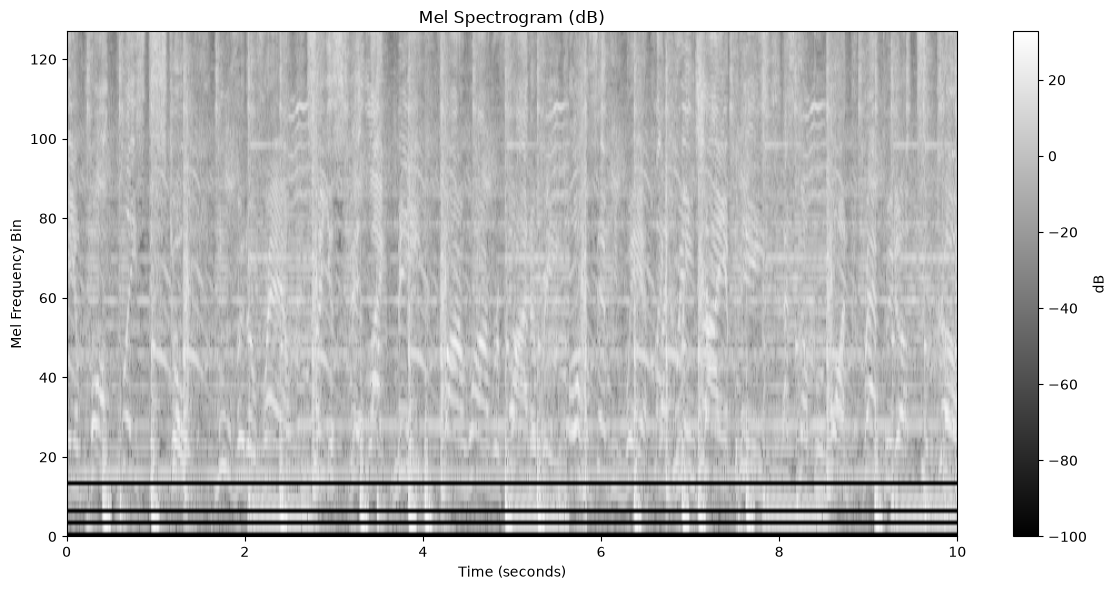

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Your mel spectrogram (dB)
# mel_db shape: (channels, n_mels, time)
mel_db_np = mel_db[0].numpy()   # take first channel

# Build time axis
num_frames = mel_db_np.shape[1]
time = np.linspace(0, center_crop.shape[1] / target_sample_rate, num_frames)

# Mel bins
mel_frequencies = np.arange(mel_db_np.shape[0])

# Plot
plt.figure(figsize=(12, 6))

plt.imshow(
    mel_db_np,
    aspect='auto',
    origin='lower',
    extent=[time.min(), time.max(), mel_frequencies.min(), mel_frequencies.max()],
    cmap='gray'
)

# Colorbar
cbar = plt.colorbar()
cbar.set_label("dB")

# Labels
plt.title("Mel Spectrogram (dB)")
plt.xlabel("Time (seconds)")
plt.ylabel("Mel Frequency Bin")

plt.tight_layout()
plt.show()

In [9]:
# Remove the channel dimension
spectrogram = mel_db[0]

print("Spectrogram shape:", spectrogram.shape)

# Transpose so time is the sequence dimension
spectrogram = spectrogram.transpose(0, 1)

print("Transformer input shape:", spectrogram.shape)

# Calculate mean and standard deviation
mean = spectrogram.mean()
std = spectrogram.std()

print("Mean before normalization:", mean.item())
print("Std before normalization:", std.item())

# Standardize
spectrogram = (spectrogram - mean) / (std + 1e-8)

print("Mean after normalization:", spectrogram.mean().item())
print("Std after normalization:", spectrogram.std().item())

Spectrogram shape: torch.Size([128, 801])
Transformer input shape: torch.Size([801, 128])
Mean before normalization: -5.831840991973877
Std before normalization: 19.172710418701172
Mean after normalization: -5.953023407556657e-09
Std after normalization: 0.9999999403953552


In [10]:
#Temporary label
label = 0

print("Label:", label)
example = (spectrogram, label)

print("Spectrogram shape:", example[0].shape)
print("Label:", example[1])

Label: 0
Spectrogram shape: torch.Size([801, 128])
Label: 0


In [11]:
import torch.nn as nn

d_model = 512

projection = nn.Linear(128, d_model)

transformer_input = projection(spectrogram)

print("Spectrogram shape:", spectrogram.shape)
print("Transformer input shape:", transformer_input.shape)

Spectrogram shape: torch.Size([801, 128])
Transformer input shape: torch.Size([801, 512])


In [12]:
# METADATA & FULL LOOP

In [ ]:
import os
import pandas as pd

# -----------------------------
# Paths
# -----------------------------

metadata_root = r"C:\X\fma-project\archive\fma_metadata\fma_metadata"

audio_root = r"C:\X\fma-project\archive\fma_small\fma_small"

metadata_path = os.path.join(metadata_root, "tracks.csv")

print("Metadata file:", metadata_path)
print("Exists:", os.path.exists(metadata_path))

In [14]:
tracks = pd.read_csv(
    metadata_path,
    header=[0, 1],
    index_col=0
)

print(tracks.head())
print(tracks.columns)

            album                                                     \
         comments         date_created        date_released engineer   
track_id                                                               
2               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
3               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
5               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
10              0  2008-11-26 01:45:08  2008-02-06 00:00:00      NaN   
20              0  2008-11-26 01:45:05  2009-01-06 00:00:00      NaN   

                                                                          \
         favorites id                                information listens   
track_id                                                                   
2                4  1                                    <p></p>    6073   
3                4  1                                    <p></p>    6073   
5                4  1                      

In [15]:
# Keep only FMA small
small_tracks = tracks[
    tracks[("set", "subset")] == "small"
].copy()

print("FMA small metadata tracks:", len(small_tracks))

track_metadata = small_tracks[
    [
        ("track", "genre_top"),
        ("set", "split")
    ]
].copy()

track_metadata.columns = ["genre", "split"]

print(track_metadata.head(10))

genre_lookup = track_metadata["genre"].to_dict()
split_lookup = track_metadata["split"].to_dict()
print("Track 2 genre:", genre_lookup.get(2))
print("Track 2 split:", split_lookup.get(2))

FMA small metadata tracks: 8000
                 genre       split
track_id                          
2              Hip-Hop    training
5              Hip-Hop    training
10                 Pop    training
140               Folk    training
141               Folk    training
148       Experimental  validation
182               Rock        test
190               Folk    training
193               Folk    training
194               Folk    training
Track 2 genre: Hip-Hop
Track 2 split: training


In [16]:
# Check for tracks with a missing genre label, even within the small subset
missing_genre_count = track_metadata["genre"].isna().sum()
print("Tracks with missing genre label:", missing_genre_count)

# Drop them -- we can't train on a track with no label
track_metadata = track_metadata.dropna(subset=["genre"])
print("Tracks remaining after dropping missing genres:", len(track_metadata))

# Rebuild lookups now that rows have been dropped
genre_lookup = track_metadata["genre"].to_dict()
split_lookup = track_metadata["split"].to_dict()


Tracks with missing genre label: 0
Tracks remaining after dropping missing genres: 8000


In [17]:
# Deterministic genre -> integer mapping, based on sorted genre names
genre_names = sorted(track_metadata["genre"].unique())
genre_to_idx = {genre: idx for idx, genre in enumerate(genre_names)}

print("Genres:", genre_names)
print("Genre to index mapping:", genre_to_idx)


Genres: ['Electronic', 'Experimental', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Pop', 'Rock']
Genre to index mapping: {'Electronic': 0, 'Experimental': 1, 'Folk': 2, 'Hip-Hop': 3, 'Instrumental': 4, 'International': 5, 'Pop': 6, 'Rock': 7}


In [ ]:
audio_index = []

for root, dirs, files in os.walk(audio_root):

    for filename in files:

        if not filename.lower().endswith(".mp3"):
            continue

        track_id = int(os.path.splitext(filename)[0])
        filepath = os.path.join(root, filename)

        audio_index.append((filepath, track_id))

print("MP3 files found:", len(audio_index))

for item in audio_index[:10]:
    print(item)


In [19]:
audio_track_ids = {track_id for filepath, track_id in audio_index}
metadata_track_ids = set(track_metadata.index)

missing_metadata = audio_track_ids - metadata_track_ids
missing_audio = metadata_track_ids - audio_track_ids

print("Audio files:", len(audio_track_ids))
print("Metadata tracks:", len(metadata_track_ids))
print("Audio without metadata:", len(missing_metadata))
print("Metadata without audio:", len(missing_audio))

Audio files: 8000
Metadata tracks: 8000
Audio without metadata: 0
Metadata without audio: 0


In [20]:
valid_track_ids = set(track_metadata.index)

audio_index_filtered = [
    (filepath, track_id)
    for filepath, track_id in audio_index
    if track_id in valid_track_ids
]

print("Original audio files:", len(audio_index))
print("Audio files with valid labels:", len(audio_index_filtered))


Original audio files: 8000
Audio files with valid labels: 8000


In [ ]:
import torch
import torch.nn.functional as F
import torchaudio


# ============================================================
# SETTINGS
# ============================================================

target_sample_rate = 16000
duration = 10
num_samples = target_sample_rate * duration


# ============================================================
# MEL SPECTROGRAM TRANSFORMS
# ============================================================

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=target_sample_rate,
    n_mels=128
)

db_transform = torchaudio.transforms.AmplitudeToDB()


# ============================================================
# LOAD AUDIO + CREATE FULL MEL SPECTROGRAM
# ============================================================

def audio_to_full_mel(filepath):
    # Load audio
    waveform, sample_rate = torchaudio.load(filepath)

    # Resample
    if sample_rate != target_sample_rate:

        waveform = torchaudio.functional.resample(
            waveform,
            sample_rate,
            target_sample_rate
        )

    # Convert stereo/multi-channel audio to mono
    waveform = waveform.mean(
        dim=0,
        keepdim=True
    )

    # Mel spectrogram
    mel = mel_transform(waveform)

    # Convert to decibels
    mel_db = db_transform(mel)

    # Remove channel dimension
    spectrogram = mel_db[0]

    # Transpose:
    # (mel bins, time) -> (time, mel bins)
    spectrogram = spectrogram.transpose(0, 1)

    return spectrogram

# CROP MEL SPECTROGRAM

# Calculate approximately how many mel frames = 10 seconds

hop_length = mel_transform.hop_length

if hop_length is None:
    hop_length = mel_transform.win_length // 2

frames_per_second = target_sample_rate / hop_length

num_mel_frames = int(
    duration * frames_per_second
)

print("Hop length:", hop_length)
print("Frames per second:", frames_per_second)
print("Mel frames for 10 seconds:", num_mel_frames)


def crop_mel(spectrogram, split):
    total_frames = spectrogram.shape[0]

    # Pad short files
    if total_frames < num_mel_frames:

        pad_amount = (
            num_mel_frames - total_frames
        )

        spectrogram = F.pad(
            spectrogram,
            (0, 0, 0, pad_amount)
        )

        total_frames = spectrogram.shape[0]

    # Training = random crop
    if split == "training":

        max_start = (
            total_frames - num_mel_frames
        )

        start = torch.randint(
            0,
            max_start + 1,
            (1,)
        ).item()

    # Validation/test = center crop
    else:

        start = (
            total_frames - num_mel_frames
        ) // 2

    crop = spectrogram[
        start:start + num_mel_frames
    ]

    return crop

def normalize_spectrogram(spectrogram):
    """
    Standardize a spectrogram to approximately mean=0,
    standard deviation=1.
    """

    mean = spectrogram.mean()
    std = spectrogram.std()

    spectrogram = (
        spectrogram - mean
    ) / (std + 1e-8)

    return spectrogram


In [ ]:
#One time run fr, just save it in case
import os
import tempfile

cache_root = r"C:\X\fma-project\mel_cache"
os.makedirs(cache_root, exist_ok=True)

successful = []
failed = []

for i, (filepath, track_id) in enumerate(audio_index_filtered):

    cache_path = os.path.join(cache_root, f"{track_id:06d}.pt")

    if os.path.exists(cache_path):
        successful.append(track_id)
        continue

    try:
        # Only this step is expected to fail for legitimate external
        # reasons (corrupted/truncated mp3, unreadable file, etc.)
        full_mel = audio_to_full_mel(filepath)

    except Exception as e:
        failed.append({
            "track_id": track_id,
            "filepath": filepath,
            "error_type": type(e).__name__,
            "error": str(e),
        })
        print(f"ERROR processing track {track_id} ({type(e).__name__}): {e}")
        continue

    # Write to a temp file, then rename. os.replace is atomic, so a
    # crash mid-write never leaves a half-written .pt file sitting at
    # the real cache path (which would otherwise look "already cached"
    # on the next run and never get retried).
    tmp_fd, tmp_path = tempfile.mkstemp(dir=cache_root, suffix=".tmp")
    os.close(tmp_fd)
    torch.save(full_mel, tmp_path)
    os.replace(tmp_path, cache_path)

    successful.append(track_id)

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(audio_index_filtered)}")

print()
print("Finished!")
print("Successful:", len(successful))
print("Failed:", len(failed))

if failed:
    failed_df = pd.DataFrame(failed)
    print(failed_df["error_type"].value_counts())


In [26]:
import glob

cache_root = r"C:\X\fma-project\mel_cache"

cached_files = glob.glob(os.path.join(cache_root, "*.pt"))
cached_track_ids = [int(os.path.splitext(os.path.basename(f))[0]) for f in cached_files]

print("Cached files found:", len(cached_track_ids))

train_data = []
val_data = []
test_data = []
skipped = 0

for track_id in cached_track_ids:
    if track_id not in genre_lookup:
        # Cached earlier under different metadata filtering, or edge case --
        # skip rather than crash a fresh-session load.
        skipped += 1
        continue

    cache_path = os.path.join(cache_root, f"{track_id:06d}.pt")
    full_mel = torch.load(cache_path)

    split = split_lookup[track_id]
    genre = genre_lookup[track_id]
    label = genre_to_idx[genre]

    cropped = crop_mel(full_mel, split)
    normalized = normalize_spectrogram(cropped)

    example = (normalized, label)

    if split == "training":
        train_data.append(example)
    elif split == "validation":
        val_data.append(example)
    elif split == "test":
        test_data.append(example)

print("Train examples:", len(train_data))
print("Validation examples:", len(val_data))
print("Test examples:", len(test_data))
print("Skipped (no metadata match):", skipped)

Cached files found: 7994
Train examples: 6394
Validation examples: 800
Test examples: 800
Skipped (no metadata match): 0
